In [1]:
import scipy.io as sio
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans


In [2]:
# Load the spike data from the .mat file
data = sio.loadmat('spikewave.mat')

# Check the structure of the data
print(data)



{'__header__': b'MATLAB 5.0 MAT-file, Platform: PCWIN, Created on: Tue Nov 08 15:46:15 2005', '__version__': '1.0', '__globals__': [], 'wave': array([[-60, 126,  15, ..., 195, 121,  -7],
       [-13, 174,  13, ..., 204, 176,  71],
       [ 37, 223,  54, ..., 176, 212, 177],
       ...,
       [-55,  67,  11, ..., -31,  25, 164],
       [-59,  57,  10, ..., -18,  12, 160],
       [-56,  65,   6, ..., -10,   7, 120]], shape=(40, 5376), dtype=int16)}


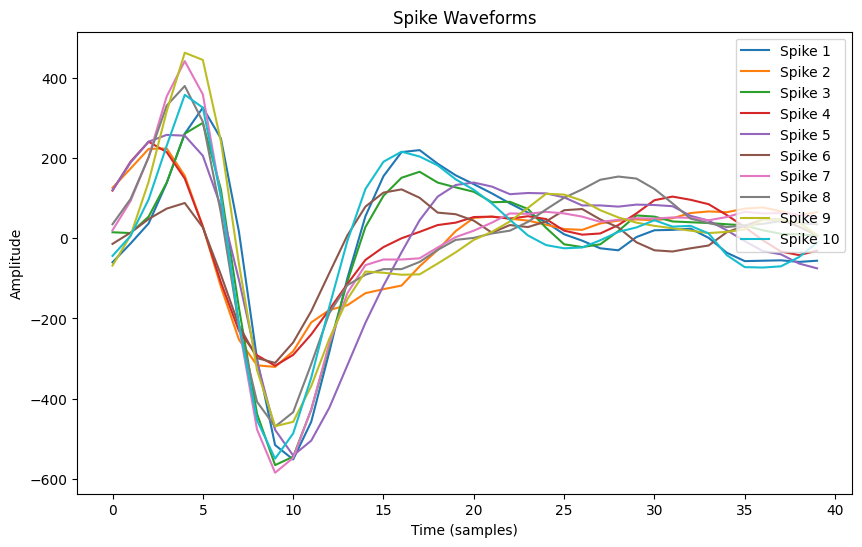

In [3]:

# Extract spike waveforms
spike_data = data['wave'].T

# Plot the first 10 spike waveforms
plt.figure(figsize=(10, 6))
for i in range(10):
    plt.plot(spike_data[i, :], label=f'Spike {i+1}')
plt.title("Spike Waveforms")
plt.xlabel("Time (samples)")
plt.ylabel("Amplitude")
plt.legend(loc='upper right')
plt.show()



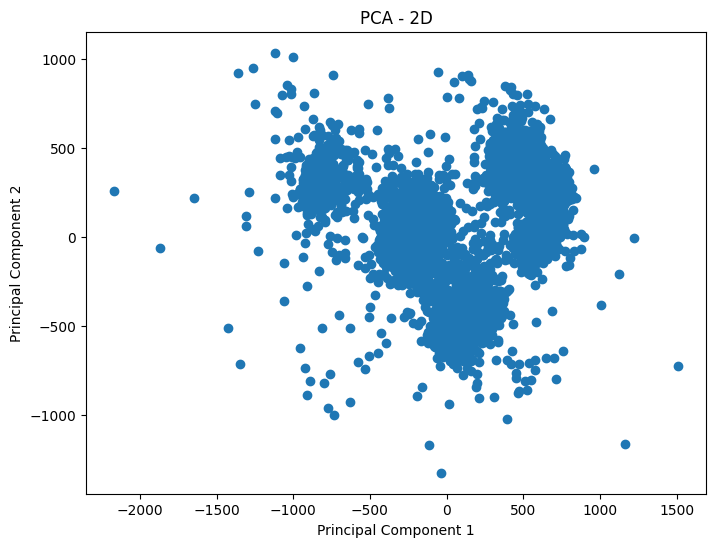

In [4]:
# Perform PCA to reduce the dimensionality to 2D and 3D
pca_2d = PCA(n_components=2)
pca_3d = PCA(n_components=3)

# Transform the spike data
spike_data_2d = pca_2d.fit_transform(spike_data)
spike_data_3d = pca_3d.fit_transform(spike_data)

# 2D PCA Plot
plt.figure(figsize=(8, 6))
plt.scatter(spike_data_2d[:, 0], spike_data_2d[:, 1])
plt.title("PCA - 2D")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()


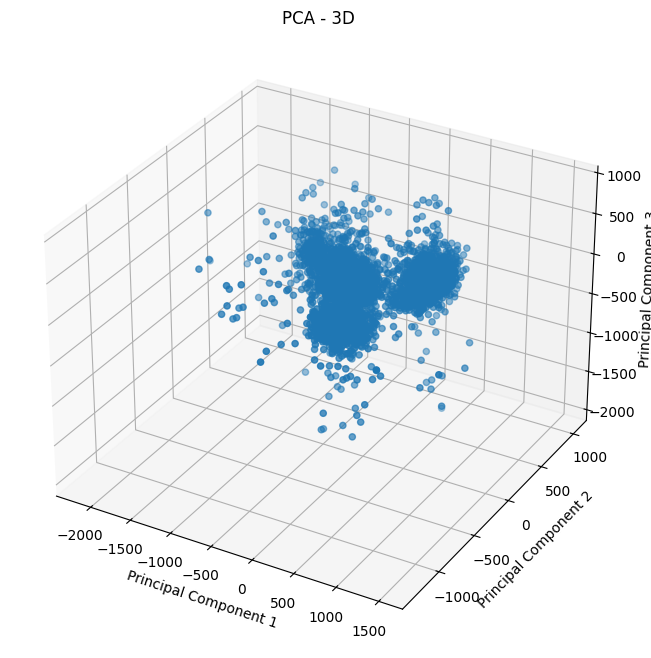

In [5]:

# 3D PCA Plot
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(spike_data_3d[:, 0], spike_data_3d[:, 1], spike_data_3d[:, 2])
ax.set_title("PCA - 3D")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.set_zlabel("Principal Component 3")
plt.show()


C:\Users\Anzam\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Anzam\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Anzam\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Anzam\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  

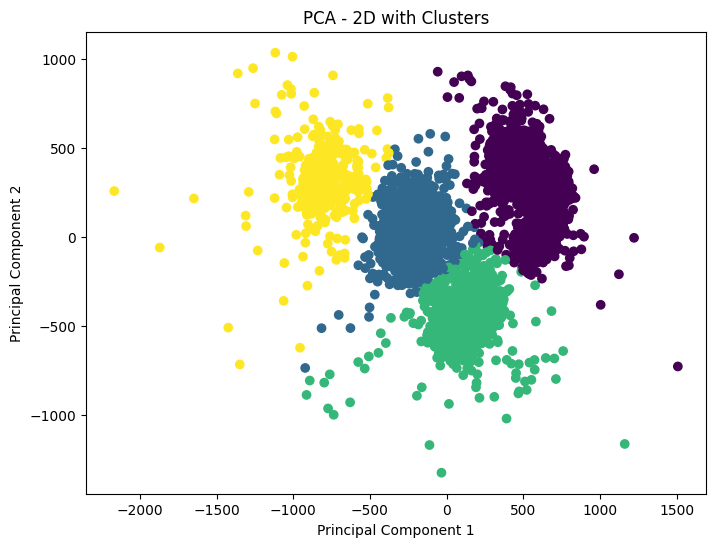

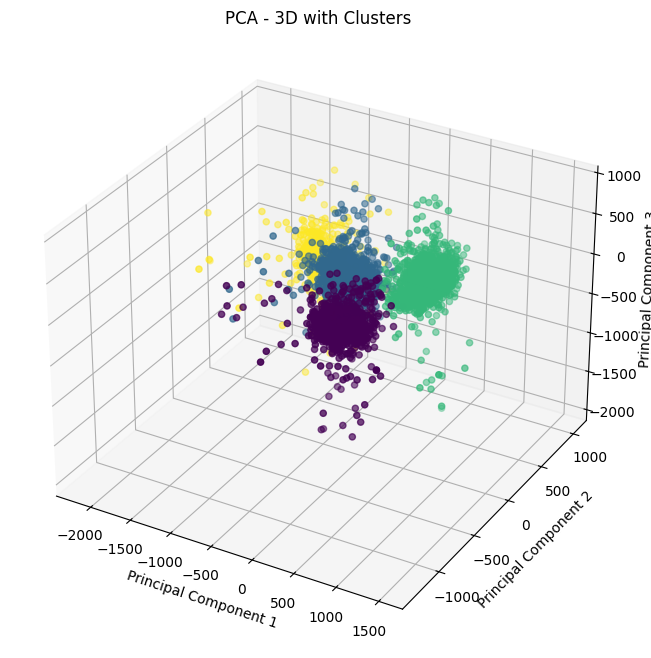

In [6]:
# Apply KMeans clustering
n_clusters = 4  # Adjust as needed
kmeans = KMeans(n_clusters=n_clusters)
clusters_2d = kmeans.fit_predict(spike_data_2d)
clusters_3d = kmeans.fit_predict(spike_data_3d)

# 2D Plot with Clustering
plt.figure(figsize=(8, 6))
plt.scatter(spike_data_2d[:, 0], spike_data_2d[:, 1], c=clusters_2d, cmap='viridis')
plt.title("PCA - 2D with Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

# 3D Plot with Clustering
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(spike_data_3d[:, 0], spike_data_3d[:, 1], spike_data_3d[:, 2], c=clusters_3d, cmap='viridis')
ax.set_title("PCA - 3D with Clusters")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.set_zlabel("Principal Component 3")
plt.show()


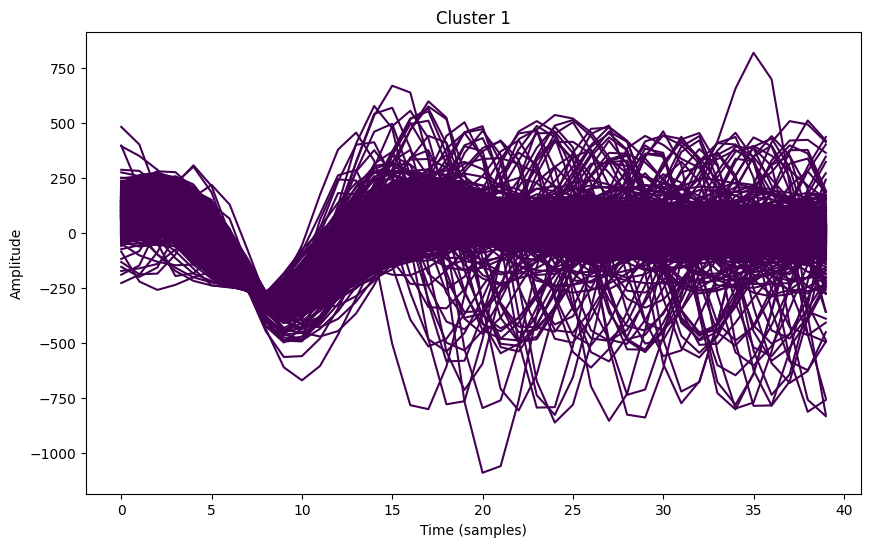

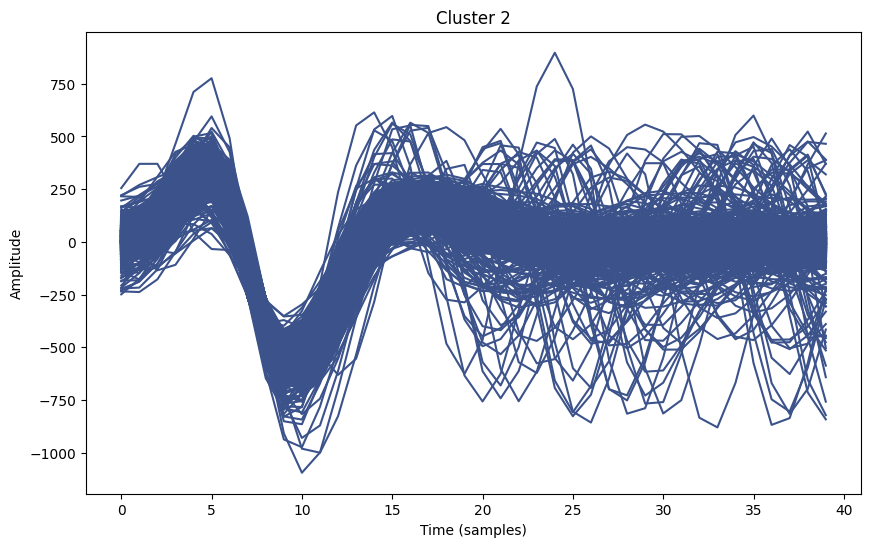

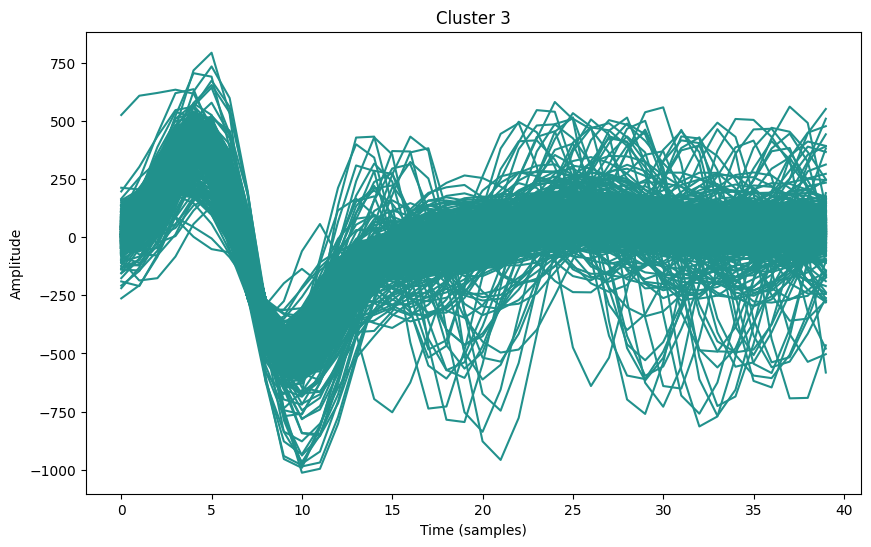

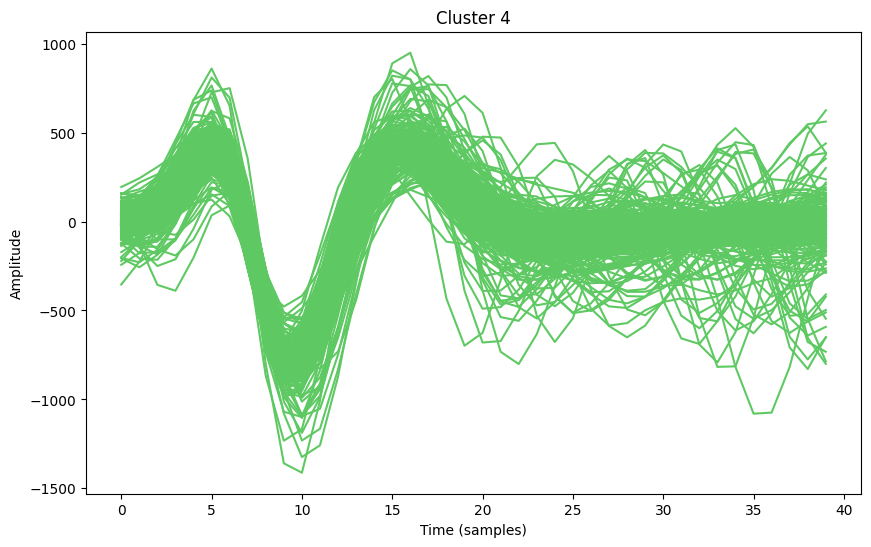

In [7]:

# Sort the spikes by their cluster assignments
sorted_spikes = [spike_data[clusters_2d == i] for i in range(n_clusters)]

# Plot each cluster with a different color
for i, cluster in enumerate(sorted_spikes):
    plt.figure(figsize=(10, 6))
    for spike in cluster:
        plt.plot(spike, color=plt.cm.viridis(i / n_clusters))
    plt.title(f"Cluster {i+1}")
    plt.xlabel("Time (samples)")
    plt.ylabel("Amplitude")
    plt.show()


